# $1)$

### Enunciado del Ejercicio: Muestreo de Gibbs y Diagnóstico de Convergencia de Gelman-Rubin

Se desea analizar el número de fallos $y_i$ registrados en $k = 10$ plantas industriales durante un tiempo de exposición conocido $t_i$ (medido en miles de horas). Los datos observados se presentan a continuación:

* **Número de fallos ($y$):** `c(5, 1, 5, 14, 3, 19, 1, 1, 4, 22)`
* **Tiempo de exposición ($t$):** `c(94.3, 15.7, 62.9, 126.0, 5.24, 31.4, 1.05, 1.05, 2.10, 10.5)`

Para modelar las tasas de fallo de cada planta, se plantea el siguiente **modelo bayesiano jerárquico**:

1. **Verosimilitud:** $y_i \mid \lambda_i \sim \text{Poisson}(\lambda_i t_i)$, para $i = 1, \dots, 10$.
2. **Distribución previa para las tasas:** $\lambda_i \mid \beta \sim \text{Gamma}(\alpha, \beta)$, donde el parámetro de forma es conocido ($\alpha = 1.8$) y el parámetro de tasa $\beta$ es desconocido.
3. **Hiperprevia:** $\beta \sim \text{Gamma}(\gamma, \delta)$, con hiperparámetros conocidos $\gamma = 0.01$ y $\delta = 1$.

A partir de esta estructura conjugada, las distribuciones condicionales completas de los parámetros son:
* $\lambda_i \mid \beta, \mathbf{y} \sim \text{Gamma}\!\left(\alpha + y_i,\; \beta + t_i\right)$
* $\beta \mid \boldsymbol{\lambda}, \mathbf{y} \sim \text{Gamma}\!\left(\gamma + k\alpha,\; \delta + \sum_{i=1}^k \lambda_i\right)$

**Se pide:**
1. Implementar en R un **Muestreador de Gibbs** para simular muestras de la distribución posterior conjunta $f(\lambda_1, \dots, \lambda_{10}, \beta \mid \mathbf{y})$.
2. Ejecutar **$m = 4$ cadenas paralelas e independientes** de $5,000$ iteraciones cada una, iniciando desde puntos sobredispersos para el hiperparámetro $\beta$: $\beta^{(0)} \in \{0.05, 0.5, 5.0, 20.0\}$.
3. Descartar las primeras $1,000$ iteraciones de cada cadena como período de calentamiento (*burn-in*) y evaluar formalmente la convergencia mediante el **estadístico $\hat{R}$ de Gelman-Rubin** para todos los parámetros del modelo, acompañando el análisis con gráficos de traza (*traceplots*).
4. Calcular y reportar las medias y desviaciones estándar posteriores de $\beta$ y de cada tasa de fallo $\lambda_i$ utilizando las muestras convergidas.

## 1

In [6]:
set.seed(2026)

# Datos observados y constantes del modelo jerárquico
y = c(5, 1, 5, 14, 3, 19, 1, 1, 4, 22)
t = c(94.3, 15.7, 62.9, 126.0, 5.24, 31.4, 1.05, 1.05, 2.10, 10.5)
k = length(y)

alpha = 1.8
gamma = 0.01
delta = 1.0

In [5]:
# 1. Función del Muestreador de Gibbs
muestreador_gibbs = function(n_iter, beta_init) {
  cadena = matrix(NA, nrow = n_iter, ncol = k + 1)
  colnames(cadena) = c(paste0("lambda_", 1:k), "beta")

  beta_act = beta_init

  for (i in 1:n_iter) {
    # Actualización vectorizada de las 10 tasas lambda_i y luego de beta
    lambda_act = rgamma(k, shape = alpha + y, rate = beta_act + t)
    beta_act = rgamma(1, shape = gamma + k * alpha, rate = delta + sum(lambda_act))

    cadena[i, ] = c(lambda_act, beta_act)
  }

  return(cadena)
}

## 2

In [7]:
# 2. Ejecutar m = 4 cadenas con puntos iniciales sobredispersos
n_iter = 5000
inicios_beta = c(0.05, 0.5, 5.0, 20.0)

cadenas = lapply(inicios_beta, function(b0) muestreador_gibbs(n_iter, b0))

## 3

 lambda_1  lambda_2  lambda_3  lambda_4  lambda_5  lambda_6  lambda_7  lambda_8 
   0.9999    0.9999    0.9999    1.0000    0.9999    0.9999    0.9999    0.9999 
 lambda_9 lambda_10      beta 
   1.0000    0.9999    0.9999 


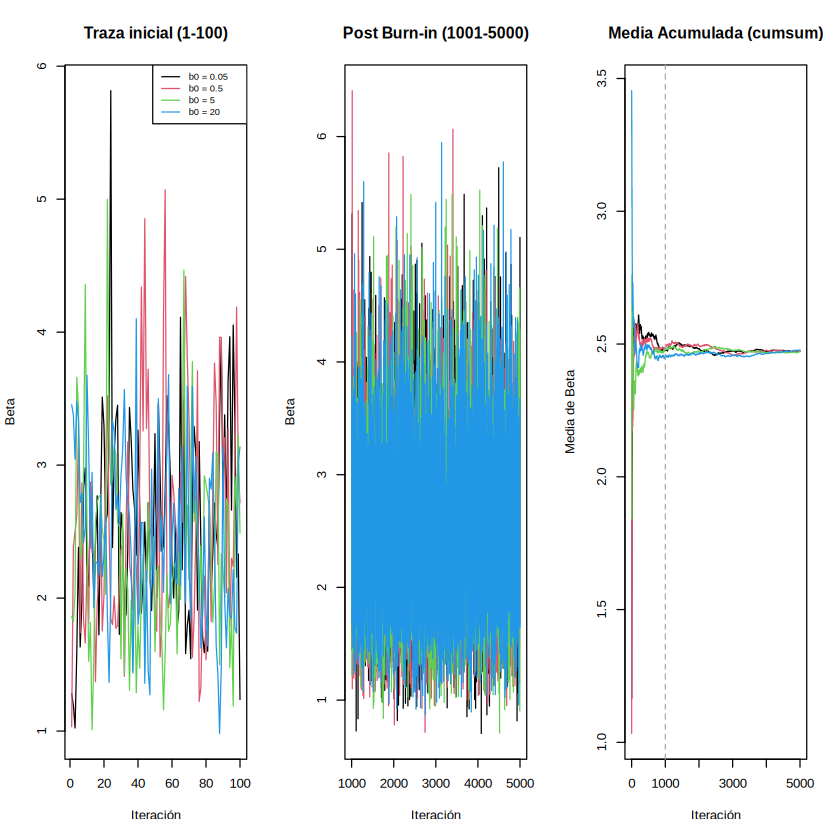

In [11]:
# 3. Descartar burn-in, calcular R-hat y graficar trazas + medias acumuladas (cumsum)
burn_in = 1000
validos = (burn_in + 1):n_iter

# Función compacta para R-hat de Gelman-Rubin
calcular_rhat = function(mat_cadenas) {
  n = nrow(mat_cadenas)
  W = mean(apply(mat_cadenas, 2, var))
  B = n * var(colMeans(mat_cadenas))
  sqrt(((n - 1) / n * W + B / n) / W)
}

# Calcular R-hat para los 11 parámetros simultáneamente
params = colnames(cadenas[[1]])
r_hat = sapply(params, function(p) {
  calcular_rhat(sapply(cadenas, function(c) c[validos, p]))
})

print(round(r_hat, 4))

# Extraer solo la columna de beta de las 4 cadenas
mat_beta = sapply(cadenas, function(c) c[, "beta"])

# Calcular medias acumuladas (ergódicas) usando cumsum en cada cadena
medias_acum = apply(mat_beta, 2, function(x) cumsum(x) / seq_along(x))

# Panel con 3 gráficos: Traza inicial, Traza post burn-in y Convergencia con cumsum
par(mfrow = c(1, 3))

# Gráfico 1: Primeras 100 iteraciones
matplot(1:100, mat_beta[1:100, ], type = "l", lty = 1,
        main = "Traza inicial (1-100)", xlab = "Iteración", ylab = "Beta")
legend("topright", legend = paste("b0 =", inicios_beta), col = 1:4, lty = 1, cex = 0.7)

# Gráfico 2: Post burn-in
matplot(validos, mat_beta[validos, ], type = "l", lty = 1,
        main = "Post Burn-in (1001-5000)", xlab = "Iteración", ylab = "Beta")

# Gráfico 3: Estabilización de la media con cumsum
matplot(1:n_iter, medias_acum, type = "l", lty = 1,
        main = "Media Acumulada (cumsum)", xlab = "Iteración", ylab = "Media de Beta")
abline(v = burn_in, col = "darkgray", lty = 2)

## 4

In [10]:
# 4. Unir muestras post-burn-in y calcular medias y desviaciones estándar

muestra_post = do.call(rbind, lapply(cadenas, function(c) c[validos, ]))

resumen = data.frame(
  Media_Posterior = round(colMeans(muestra_post), 4),
  Desv_Estandar   = round(apply(muestra_post, 2, sd), 4),
  R_hat           = round(r_hat, 4)
)

print(resumen)

          Media_Posterior Desv_Estandar  R_hat
lambda_1           0.0698        0.0267 0.9999
lambda_2           0.1544        0.0918 0.9999
lambda_3           0.1031        0.0401 0.9999
lambda_4           0.1233        0.0312 1.0000
lambda_5           0.6263        0.2894 0.9999
lambda_6           0.6145        0.1344 0.9999
lambda_7           0.8243        0.5241 0.9999
lambda_8           0.8247        0.5228 0.9999
lambda_9           1.2972        0.5811 1.0000
lambda_10          1.8434        0.3890 0.9999
beta               2.4740        0.7114 0.9999


### Conclusiones

* Rápida convergencia y eliminación de la dependencia inicial: En el primer gráfico de traza (iteraciones 1 a 100) se observa cómo las cuatro cadenas parten de valores muy dispersos ($\beta^{(0)} \in \{0.05, 0.5, 5.0, 20.0\}$), pero convergen hacia la misma región estacionaria en las primeras iteraciones. Esto demuestra que el período de calentamiento (burn-in) de $1,000$ iteraciones es más que suficiente para eliminar el sesgo causado por los puntos de partida.

* Mezcla estacionaria óptima (good mixing) post burn-in: En el segundo gráfico (iteraciones 1,001 a 5,000), las cuatro trayectorias se superponen constantemente formando una banda horizontal estable alrededor de una media constante, sin tendencias ni bloqueos prolongados. Esta evidencia visual se respalda numéricamente con los estadísticos de Gelman-Rubin ($\hat{R} \approx 1.000$ para todos los parámetros), confirmando que la varianza entre cadenas es prácticamente igual a la varianza dentro de cada cadena y que el muestreador explora adecuadamente toda la distribución posterior.

* Eficiencia del Muestreador de Gibbs en modelos jerárquicos conjugados: Aprovechar las distribuciones condicionales completas (todas de tipo Gamma) permitió actualizar los 11 parámetros del modelo de forma exacta y con una tasa de aceptación del 100%, evitando problemas de ajuste (tuning) propios de otros algoritmos MCMC. Gracias a la estabilización de $\beta$, se obtienen estimaciones posteriores precisas para las tasas de fallo individuales ($\lambda_i$), suavizando de manera natural las estimaciones de aquellas plantas que contaban con tiempos de exposición muy cortos.

# $2$)

### Enunciado del Ejercicio: Muestreo de Gibbs en un Modelo Jerárquico Normal-Normal y Diagnóstico de Gelman-Rubin

Se desea analizar el rendimiento promedio en una prueba estandarizada aplicado a $k = 8$ colegios distintos. En cada colegio $i$, se conoce la media muestral observada $\bar{y}_i$ obtenida a partir de una muestra de tamaño $n_i = 25$ estudiantes, con una varianza muestral conocida dentro de cada grupo $\sigma^2 = 100$:

* **Medias muestrales observadas ($\bar{y}$):** `c(62.5, 58.0, 71.2, 65.4, 54.8, 69.0, 60.1, 67.3)`
* **Tamaño de muestra por colegio ($n_i$):** $25$ estudiantes en cada grupo ($k = 8$).
* **Varianza conocida dentro de cada colegio ($\sigma^2$):** $100$.

Para estimar el puntaje medio real $\theta_i$ de cada colegio y el promedio general del distrito $\mu$, se plantea el siguiente **modelo bayesiano jerárquico**:

1. **Verosimilitud:** $\bar{y}_i \mid \theta_i \sim \mathcal{N}\!\left(\theta_i,\; \frac{\sigma^2}{n_i}\right)$, para $i = 1, \dots, 8$.
2. **Distribución previa para las medias grupales:** $\theta_i \mid \mu, \tau^2 \sim \mathcal{N}(\mu, \tau^2)$, donde $\mu$ es la media global desconocida y $\tau^2 = 25$ es la varianza entre colegios (supuesta conocida).
3. **Hiperprevia:** $\mu \sim \mathcal{N}(\mu_0, \sigma_0^2)$, con hiperparámetros conocidos $\mu_0 = 60$ y $\sigma_0^2 = 400$.

A partir de esta estructura conjugada, las distribuciones condicionales completas de los parámetros son:
* $\theta_i \mid \mu, \mathbf{y} \sim \mathcal{N}\!\left(\frac{\frac{n_i}{\sigma^2}\bar{y}_i + \frac{1}{\tau^2}\mu}{\frac{n_i}{\sigma^2} + \frac{1}{\tau^2}},\; \left(\frac{n_i}{\sigma^2} + \frac{1}{\tau^2}\right)^{-1}\right)$
* $\mu \mid \boldsymbol{\theta}, \mathbf{y} \sim \mathcal{N}\!\left(\frac{\frac{1}{\tau^2}\sum_{i=1}^k \theta_i + \frac{1}{\sigma_0^2}\mu_0}{\frac{k}{\tau^2} + \frac{1}{\sigma_0^2}},\; \left(\frac{k}{\tau^2} + \frac{1}{\sigma_0^2}\right)^{-1}\right)$

**Se pide:**
1. Implementar en R un **Muestreador de Gibbs** para simular muestras de la distribución posterior conjunta $f(\theta_1, \dots, \theta_8, \mu \mid \mathbf{y})$.
2. Ejecutar **$m = 4$ cadenas paralelas e independientes** de $5,000$ iteraciones cada una, iniciando desde puntos sobredispersos para el hiperparámetro $\mu$: $\mu^{(0)} \in \{10, 40, 85, 120\}$.
3. Descartar las primeras $1,000$ iteraciones de cada cadena como período de calentamiento (*burn-in*) y evaluar la convergencia mediante el **estadístico $\hat{R}$ de Gelman-Rubin**, acompañando el análisis con gráficos de traza (*traceplots*) y promedios acumulados (`cumsum`).
4. Calcular y reportar las medias y desviaciones estándar posteriores de $\mu$ y de cada media grupal $\theta_i$ utilizando las muestras convergidas.

## 1

In [12]:
set.seed(2026)

# Datos observados y constantes del modelo jerárquico Normal-Normal
y_bar = c(62.5, 58.0, 71.2, 65.4, 54.8, 69.0, 60.1, 67.3)
k = length(y_bar)
n_i = 25

sigma2 = 100
tau2 = 25
mu_0 = 60
sigma2_0 = 400

In [13]:
# 1. Función del Muestreador de Gibbs
muestreador_gibbs = function(n_iter, mu_init) {
  cadena = matrix(NA, nrow = n_iter, ncol = k + 1)
  colnames(cadena) = c(paste0("theta_", 1:k), "mu")

  # Precisiones constantes (inversas de las varianzas) para optimizar el bucle
  prec_y = n_i / sigma2
  prec_tau = 1 / tau2
  prec_0 = 1 / sigma2_0

  sd_theta = sqrt(1 / (prec_y + prec_tau))
  sd_mu = sqrt(1 / (k * prec_tau + prec_0))

  mu_act = mu_init

  for (i in 1:n_iter) {
    # Paso A: Actualizar vectorizado los 8 puntajes theta_i dado mu_act
    media_theta = (prec_y * y_bar + prec_tau * mu_act) / (prec_y + prec_tau)
    theta_act = rnorm(k, mean = media_theta, sd = sd_theta)

    # Paso B: Actualizar la media global mu dado el vector recién actualizado theta_act
    media_mu = (prec_tau * sum(theta_act) + prec_0 * mu_0) / (k * prec_tau + prec_0)
    mu_act = rnorm(1, mean = media_mu, sd = sd_mu)

    cadena[i, ] = c(theta_act, mu_act)
  }

  return(cadena)
}

## 2

In [14]:
# 2. Ejecutar m = 4 cadenas con puntos iniciales sobredispersos para mu
n_iter = 5000
inicios_mu = c(10, 40, 85, 120)

cadenas = lapply(inicios_mu, function(m0) muestreador_gibbs(n_iter, m0))

## 3

theta_1 theta_2 theta_3 theta_4 theta_5 theta_6 theta_7 theta_8      mu 
 0.9999  0.9999  0.9999  1.0000  0.9999  1.0000  1.0000  1.0000  0.9999 


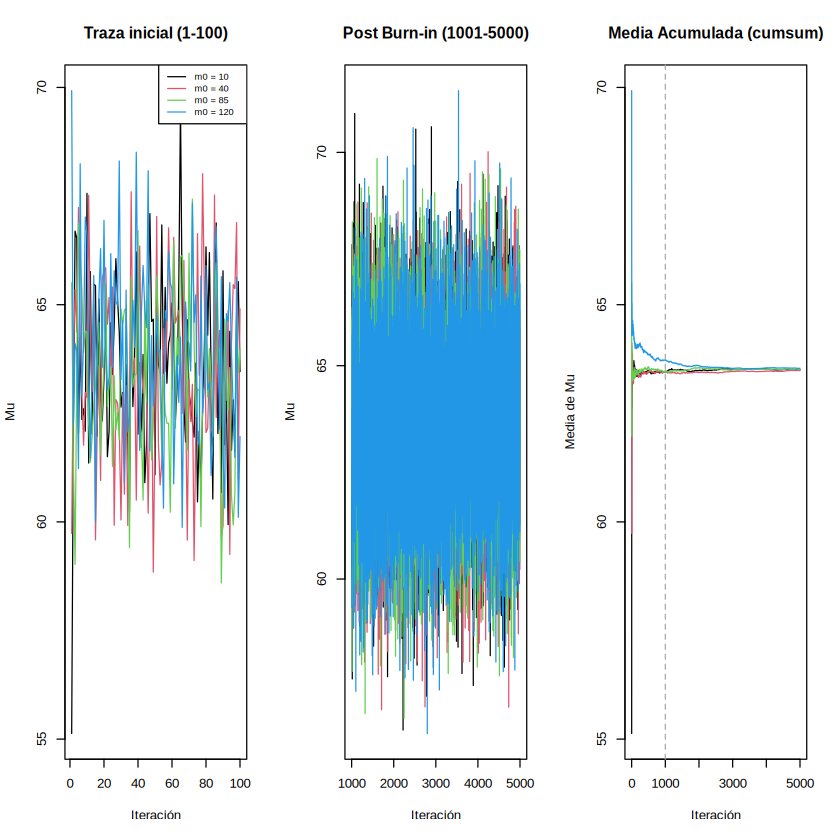

In [15]:
# 3. Descartar burn-in, calcular R-hat y graficar trazas + medias acumuladas (cumsum)
burn_in = 1000
validos = (burn_in + 1):n_iter

# Función compacta para R-hat de Gelman-Rubin
calcular_rhat = function(mat_cadenas) {
  n = nrow(mat_cadenas)
  W = mean(apply(mat_cadenas, 2, var))
  B = n * var(colMeans(mat_cadenas))
  sqrt(((n - 1) / n * W + B / n) / W)
}

# Calcular R-hat para los 9 parámetros simultáneamente
params = colnames(cadenas[[1]])
r_hat = sapply(params, function(p) {
  calcular_rhat(sapply(cadenas, function(c) c[validos, p]))
})

print(round(r_hat, 4))

# Extraer solo la columna de mu de las 4 cadenas y calcular medias acumuladas con cumsum
mat_mu = sapply(cadenas, function(c) c[, "mu"])
medias_acum = apply(mat_mu, 2, function(x) cumsum(x) / seq_along(x))

# Panel con 3 gráficos: Traza inicial, Traza post burn-in y Convergencia con cumsum
par(mfrow = c(1, 3))

matplot(1:100, mat_mu[1:100, ], type = "l", lty = 1,
        main = "Traza inicial (1-100)", xlab = "Iteración", ylab = "Mu")
legend("topright", legend = paste("m0 =", inicios_mu), col = 1:4, lty = 1, cex = 0.7)

matplot(validos, mat_mu[validos, ], type = "l", lty = 1,
        main = "Post Burn-in (1001-5000)", xlab = "Iteración", ylab = "Mu")

matplot(1:n_iter, medias_acum, type = "l", lty = 1,
        main = "Media Acumulada (cumsum)", xlab = "Iteración", ylab = "Media de Mu")
abline(v = burn_in, col = "darkgray", lty = 2)

## 4

In [16]:
# 4. Unir muestras post-burn-in y calcular medias y desviaciones estándar
muestra_post = do.call(rbind, lapply(cadenas, function(c) c[validos, ]))

resumen = data.frame(
  Media_Muestral  = c(y_bar, NA),
  Media_Posterior = round(colMeans(muestra_post), 4),
  Desv_Estandar   = round(apply(muestra_post, 2, sd), 4),
  R_hat           = round(r_hat, 4)
)

print(resumen)

        Media_Muestral Media_Posterior Desv_Estandar  R_hat
theta_1           62.5         62.6509        1.8773 0.9999
theta_2           58.0         58.7883        1.8684 0.9999
theta_3           71.2         70.1380        1.8841 0.9999
theta_4           65.4         65.1102        1.8846 1.0000
theta_5           54.8         56.0270        1.8578 0.9999
theta_6           69.0         68.2416        1.8750 1.0000
theta_7           60.1         60.5779        1.8860 1.0000
theta_8           67.3         66.7897        1.8834 1.0000
mu                  NA         63.5050        1.8954 0.9999


### Conclusiones

* Eliminación rápida del sesgo inicial y estabilización ergódica: En el primer gráfico de traza (iteraciones 1 a 100) y en el gráfico de promedios acumulados (cumsum), se observa que aunque las cuatro cadenas parten de valores extremos ($\mu^{(0)} \in \{10, 40, 85, 120\}$), convergen casi de inmediato hacia el entorno de $\mu \approx 63.5$. Las curvas de medias acumuladas se superponen en una línea horizontal constante mucho antes de llegar a la línea punteada del burn-in (1000), demostrando que el período de calentamiento elegido es totalmente adecuado.

* Convergencia formal confirmada por el estadístico de Gelman-Rubin: En el gráfico post burn-in (iteraciones 1,001 a 5,000), las cuatro trayectorias muestran una excelente mezcla estacionaria (good mixing), fluctuando alrededor de la misma media con varianza constante y sin tendencias. Esto se corrobora cuantitativamente al obtener $\hat{R} \approx 1.000$ en los 9 parámetros del modelo (muy por debajo del límite de $1.05$), confirmando que la variabilidad entre cadenas coincide con la variabilidad interna de cada cadena.

* Efecto de contracción (shrinkage) propio de los modelos jerárquicos: Al comparar la columna Media_Muestral frente a Media_Posterior en la tabla final, se evidencia cómo el modelo bayesiano jerárquico desplaza ligeramente las estimaciones individuales $\theta_i$ hacia la media global del distrito ($\mu \approx 63.5$). Este comportamiento reduce el ruido muestral de los colegios con resultados más extremos (como el colegio 3 con $71.2$ o el colegio 5 con $54.8$), aprovechando la información compartida entre todos los grupos.